In [7]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

con = duckdb.connect("jupiter_lend.duckdb")

In [8]:
query = """
SELECT
    timestamp,
    debt_repaid_usd,
    sol_close
FROM liquidation_analysis_5m
WHERE timestamp >= TIMESTAMP '2025-10-10 00:00:00'
  AND timestamp < TIMESTAMP '2025-10-11 00:00:00'
ORDER BY timestamp
"""

df = con.execute(query).df()

df.head()

,timestamp,debt_repaid_usd,sol_close
0,2025-10-10 00:00:00,0.0,221.25
1,2025-10-10 00:05:00,0.0,221.54
2,2025-10-10 00:10:00,0.0,221.48
3,2025-10-10 00:15:00,0.0,221.59
4,2025-10-10 00:20:00,0.0,221.39


In [9]:
df["timestamp"] = pd.to_datetime(df["timestamp"])

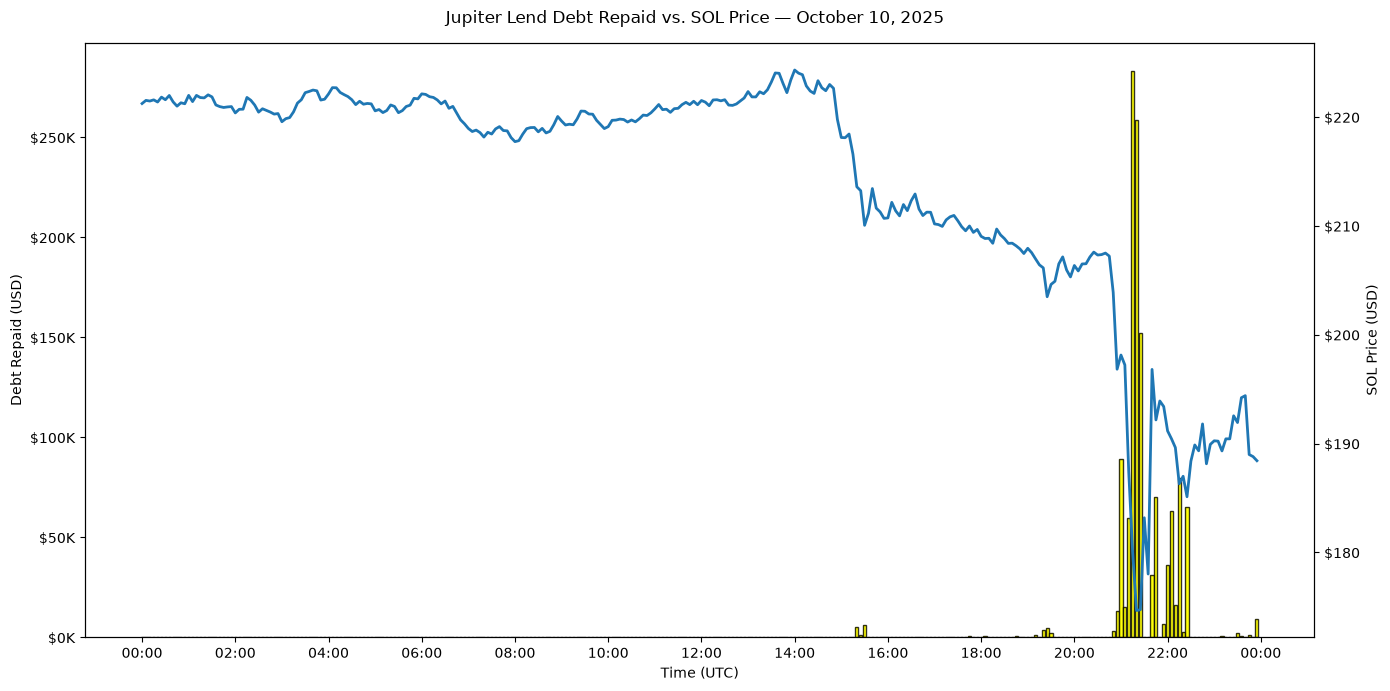

In [12]:
fig, ax1 = plt.subplots(figsize=(14, 7))

# Bars: debt repaid
bar_width = 4 / (24 * 60)  # ~4 minutes as fraction of a day

ax1.bar(
    df["timestamp"],
    df["debt_repaid_usd"],
    width=bar_width,
    color="yellow",
    alpha=0.8
)

ax1.set_xlabel("Time (UTC)")
ax1.set_ylabel("Debt Repaid (USD)")

ax1.yaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"${x/1000:.0f}K")
)

# Second Y-axis: SOL price
ax2 = ax1.twinx()

ax2.plot(
    df["timestamp"],
    df["sol_close"],
    linewidth=2
)

ax2.set_ylabel("SOL Price (USD)")
ax2.yaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"${x:,.0f}")
)

ax1.bar(
    df["timestamp"],
    df["debt_repaid_usd"],
    width=bar_width,
    color="yellow",
    edgecolor="black",
    alpha=0.8
)

# Time formatting
ax1.xaxis.set_major_locator(mdates.HourLocator(interval=2))
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))

fig.suptitle("Jupiter Lend Debt Repaid vs. SOL Price — October 10, 2025")

fig.tight_layout()
plt.show()